# 08 — Compound splitter + compound-density analysis (Step 3 + Step 4)

**Proshno:** compound word beshi thakle ki retrieval kharap hoy? (RQ2)

**Splitter choice (notun):** main splitter = **CompoundPiece** (Minixhofer et al., EMNLP 2023; neural, publicly released `benjamin/compoundpiece`).
**Koehn & Knight (frequency)** baseline hishebe rakhchi. Dutoi **ek-i manual sample**-e validate kori, tarpor data dekhe choose kori (assumption na).

Ei notebook-e:
1. K&K baseline splitter (`src/compound.py`) + CompoundPiece splitter
2. **Manual validation sheet** (150 shobd), tumi label korbe; dutoi splitter-er precision/recall
3. Prottek query-r **compound density** = compound shobd / total shobd (main splitter diye)
4. v2 baseline-er per-query nDCG@10 (BM25 / Dense / Hybrid) density bin onujayi, CI shoho
5. Query length control

**Age lagbe:**
- `src/compound.py` (notun version, CompoundPiece class shoho) repo-te push
- `07_hybrid_fixed`-er output (`baselines_v2_perquery.jsonl`) Add Input kora

**Kaggle:** **GPU On** (CompoundPiece-er jonno), Internet On.

In [1]:
!pip install datasets rank_bm25 statsmodels -q

In [2]:
import os, sys, subprocess, glob, json, shutil
REPO_URL = "https://github.com/medhuuuu/swedish-retrieval-project.git"
REPO_DIR = "/kaggle/working/swedish-retrieval-project"
if os.path.exists(REPO_DIR):
    print(subprocess.run(["git", "-C", REPO_DIR, "pull"], capture_output=True, text=True).stdout)
else:
    print(subprocess.run(["git", "clone", REPO_URL, REPO_DIR], capture_output=True, text=True))
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path: sys.path.insert(0, REPO_DIR)

BASE = "/kaggle/working/swedish_retrieval"
CACHE_DIR = os.path.join(BASE, "cache"); os.makedirs(CACHE_DIR, exist_ok=True)
RES_DIR = os.path.join(REPO_DIR, "results"); os.makedirs(RES_DIR, exist_ok=True)

def find_file(name):
    # 1) Kaggle input (ager notebook-er output), 2) repo results/
    for p in glob.glob(f"/kaggle/input/**/{name}", recursive=True) + [os.path.join(RES_DIR, name)]:
        if os.path.exists(p): return p
    return None

PERQ = find_file("/kaggle/input/notebooks/tanjilaahmed/07-hybrid-fixed/swedish-retrieval-project/results/baselines_v2_perquery.jsonl")
print("per-query file:", PERQ)
assert PERQ, "baselines_v2_perquery.jsonl pai nai: 07 notebook-er output Add Input koro"

from src.compound import (CompoundSplitter, CompoundPieceSplitter, words_of, build_freq,
                          save_freq, load_freq, density)
from src.utils import load_swefaq, load_swedn, build_qrels_dict

CompletedProcess(args=['git', 'clone', 'https://github.com/medhuuuu/swedish-retrieval-project.git', '/kaggle/working/swedish-retrieval-project'], returncode=0, stdout='', stderr="Cloning into '/kaggle/working/swedish-retrieval-project'...\n")
per-query file: /kaggle/input/notebooks/tanjilaahmed/07-hybrid-fixed/swedish-retrieval-project/results/baselines_v2_perquery.jsonl


In [3]:
swefaq_corpus, swefaq_queries, swefaq_qrels = load_swefaq()
swedn_corpus, swedn_queries, swedn_qrels = load_swedn()
qrels = {"swefaq": build_qrels_dict(swefaq_qrels), "swedn": build_qrels_dict(swedn_qrels)}
doc_text = {"swefaq": {d["_id"]: d["text"] for d in swefaq_corpus},
            "swedn":  {d["_id"]: d["text"] for d in swedn_corpus}}
query_text = {"swefaq": {q["_id"]: q["text"] for q in swefaq_queries},
              "swedn":  {q["_id"]: q["text"] for q in swedn_queries}}
print({k: len(v) for k, v in doc_text.items()}, {k: len(v) for k, v in query_text.items()})

README.md:   0%|          | 0.00/6.41k [00:00<?, ?B/s]

corpus/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 88.9kB            

corpus/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/511 [00:00<?, ? examples/s]

queries/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.5kB            

queries/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (38 outputs left out)

Map:   0%|          | 0/2046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

{'swefaq': 511, 'swedn': 6141} {'swefaq': 513, 'swedn': 3072}


## 1. Swedish word-frequency list

K&K splitter-er jonno boro frequency list lage (tomar dui dataset-er text onek chhoto). Ami **Swedish Wikipedia**-r prothom ~150k article theke frequency banai, sathe dui dataset-er corpus-o jog kori (shudhu shobder gonona, kono label na, tai unsupervised, kono leak nei).
Ekbar banale cache hoye thake.

In [4]:
from collections import Counter
FREQ_PATH = os.path.join(CACHE_DIR, "sv_freq.json")
restored = find_file("sv_freq.json")
if restored and not os.path.exists(FREQ_PATH):
    shutil.copy(restored, FREQ_PATH)

if os.path.exists(FREQ_PATH):
    freq = load_freq(FREQ_PATH); print("freq cache hit:", len(freq), "types")
else:
    freq = Counter()
    try:
        from datasets import load_dataset
        wiki = load_dataset("wikimedia/wikipedia", "20231101.sv", split="train", streaming=True)
        for i, art in enumerate(wiki):
            build_freq([art["text"]], freq)
            if i + 1 >= 150_000: break
        print("wikipedia articles used:", i + 1)
    except Exception as e:
        print("!! Wikipedia load fail:", repr(e), "\n!! Fallback: shudhu dui dataset corpus (kom accurate hobe)")
    for ds in doc_text:
        build_freq(doc_text[ds].values(), freq)
    save_freq(freq, FREQ_PATH)
    print("freq built:", len(freq), "types,", sum(freq.values()), "tokens")
for w in ["och", "gång", "rund", "rundgång", "förlossningen"]:
    print(w, freq.get(w, 0))

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

wikipedia articles used: 150000
freq built: 1393479 types, 55628401 tokens
och 1797976
gång 13164
rund 536
rundgång 67
förlossningen 228


## 2. Baseline: Koehn & Knight (frequency) splitter
Rule: whole word-er frequency-r cheye parts-er geometric-mean frequency beshi hole split. Part min 3 akshor, freq >= 30, max 3 part, linking `s/e/a/o`.
Eta **baseline**; main splitter porer section-e.

In [5]:
kk = CompoundSplitter(freq, min_part_len=3, min_part_freq=30, min_word_len=7, max_parts=3)
demo = ["rundgång", "föräldrapenning", "sjukförsäkring", "förlossningen", "webben", "lördagar",
        "vindkraftverk", "cykelbana", "arbetsgivare", "kommunfullmäktige", "barnbidrag", "rekommendationer"]
for w in demo: print(f"{w:22s} -> {kk.split(w)}")

rundgång               -> ['rund', 'gång']
föräldrapenning        -> ['föräldrapenning']
sjukförsäkring         -> ['sjuk', 'för', 'säkring']
förlossningen          -> ['förlossningen']
webben                 -> ['webben']
lördagar               -> ['lördagar']
vindkraftverk          -> ['vind', 'kraft', 'verk']
cykelbana              -> ['cykel', 'bana']
arbetsgivare           -> ['arbetsgivare']
kommunfullmäktige      -> ['kommun', 'fullmäktige']
barnbidrag             -> ['barn', 'bidrag']
rekommendationer       -> ['rekommendationer']


## 3. Main splitter: CompoundPiece (neural)
Model `benjamin/compoundpiece` (T5-style, MIT license, 56 language-er jonno train kora). Ekta shobd dile hyphen diye parts dey (e.g. *Hauswirtschaftslehre → Haus-Wirtschaft-Lehre*).
**Swedish-e kemon kaj kore seta amra nijera check korbo**, nicher demo + manual validation-e. (Model card-e language list nai, tai assume korchi na.)

Model shudhu **unique shobd**-e chalate hobe (query + relevant document-er shobd, length >= 7), result cache hoy (`cp_cache.json`), tai ekbar-i dami.

In [6]:
CP_CACHE = os.path.join(CACHE_DIR, "cp_cache.json")
restored = find_file("cp_cache.json")
if restored and not os.path.exists(CP_CACHE):
    shutil.copy(restored, CP_CACHE)
cp = CompoundPieceSplitter(cache_path=CP_CACHE, min_word_len=7)

demo_cp = ["rundgång", "föräldrapenning", "sjukförsäkring", "förlossningen", "webben", "lördagar",
           "vindkraftverk", "cykelbana", "arbetsgivare", "kommunfullmäktige", "barnbidrag", "rekommendationer"]
cp.precompute(demo_cp)
print(f"{'word':22s} {'CompoundPiece':32s} K&K")
for w in demo_cp: print(f"{w:22s} {str(cp.split(w)):32s} {kk.split(w)}")

CompoundPiece: 11 new words (0 cached)


config.json:   0%|          | 0.00/792 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.50k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/3.09k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

word                   CompoundPiece                    K&K
rundgång               ['rund', 'gång']                 ['rund', 'gång']
föräldrapenning        ['föräldra', 'penning']          ['föräldrapenning']
sjukförsäkring         ['sjuk', 'försäkring']           ['sjuk', 'för', 'säkring']
förlossningen          ['förlossningen']                ['förlossningen']
webben                 ['webben']                       ['webben']
lördagar               ['lördagar']                     ['lördagar']
vindkraftverk          ['vind', 'kraft', 'verk']        ['vind', 'kraft', 'verk']
cykelbana              ['cykel', 'bana']                ['cykel', 'bana']
arbetsgivare           ['arbete', 'givare']             ['arbetsgivare']
kommunfullmäktige      ['kommun', 'fullmäktig']         ['kommun', 'fullmäktige']
barnbidrag             ['barn', 'bidrag']               ['barn', 'bidrag']
rekommendationer       ['rekommendationer']             ['rekommendationer']


### Shob query + relevant-document shobd-e CompoundPiece chalai
Prothome **query-r shobd** (choto, druto), tarpor **relevant document-er shobd** (boro: Swedn-e kichu minute lagte pare, cache hoye thakbe).
Jodi doc-side onek slow hoy, `DOC_SIDE = False` korle shudhu query-side density hobe (RQ2-r main kaj), document-side bin skip.

In [7]:
import time
DOC_SIDE = True
q_words = {w for ds in query_text for t in query_text[ds].values() for w in words_of(t)}
t0 = time.time(); cp.precompute(q_words); print("query words done:", round(time.time() - t0), "s")

if DOC_SIDE:
    d_words = set()
    for ds in qrels:
        rel_docs = {d for q in qrels[ds] for d in qrels[ds][q]}
        for d in rel_docs: d_words.update(words_of(doc_text[ds][d]))
    print("relevant-doc vocab (len>=7):", sum(len(w) >= 7 for w in d_words))
    t0 = time.time(); cp.precompute(d_words); print("doc words done:", round(time.time() - t0), "s")

CompoundPiece: 4942 new words (11 cached)
query words done: 27 s
relevant-doc vocab (len>=7): 94320
CompoundPiece: 89987 new words (4953 cached)
  6400/89987
  12800/89987
  19200/89987
  25600/89987
  32000/89987
  38400/89987
  44800/89987
  51200/89987
  57600/89987
  64000/89987
  70400/89987
  76800/89987
  83200/89987
  89600/89987
doc words done: 640 s


## 4. Manual validation sample (150 shobd) — TOMAR KAJ

150 ta random shobd (query theke, length >= 6) CSV-te save hobe, **duita splitter-er output** shoho. **Tumi** nijer chokhe label korbe:
- `true_compound`: **1** jodi sotti compound (*rundgång*), **0** jodi na (*förlossningen*, *lördagar*)
- `true_split`: **jodi true_compound = 1 hoy, sothik part likho space diye** (e.g. `rund gång`). Non-compound-e faka rakho.
  (Dutoi splitter-er nijer output tomar answer-er shathe milabe, tai shob compound-e true_split likhte hobe.)

File-er naam `compound_validation_labeled.csv` kore repo-r `results/`-e push koro. Notebook abar chalale dutoi splitter-er precision/recall nije hishab hobe.

In [8]:

import random, pandas as pd
vocab = sorted({w for ds in query_text for t in query_text[ds].values() for w in words_of(t) if len(w) >= 6})
random.Random(0).shuffle(vocab)
sample = vocab[:150]
cp.precompute(sample)
val = pd.DataFrame({"word": sample,
                    "kk_parts": [" ".join(kk.split(w)) for w in sample],
                    "cp_parts": [" ".join(cp.split(w)) for w in sample],
                    "true_compound": "", "true_split": "", "notes": ""})
val.to_csv(os.path.join(RES_DIR, "compound_validation_sample.csv"), index=False)
print("query vocab (len>=6):", len(vocab),
      "| K&K splits", int(val.kk_parts.str.contains(" ").sum()), "/ 150",
      "| CompoundPiece splits", int(val.cp_parts.str.contains(" ").sum()), "/ 150")
val.head(15)


CompoundPiece: 0 new words (94940 cached)
query vocab (len>=6): 6135 | K&K splits 75 / 150 | CompoundPiece splits 71 / 150


,word,kk_parts,cp_parts,true_compound,true_split,notes
0,inleder,inleder,in leder,,,
1,jättelätt,jätte lätt,jätt lätt,,,
2,dalagatan,dal gatan,dal gata,,,
3,tordes,tordes,tordes,,,
4,mixedstafettlaget,mixed stafett laget,mixed stafett laget,,,
5,etanolen,etan len,etanolen,,,
6,lägger,lägger,lägger,,,
7,anklagar,anklagar,an klagar,,,
8,hultquist,hult quist,hult quist,,,
9,muslimer,muslimer,muslimer,,,


In [9]:

lab_path = find_file("compound_validation_labeled.csv")
CHOSEN = "cp"          # label-er por data dekhe bodlaite paro: "cp" ba "kk"
if not lab_path:
    print("Label file ekhono nai: ekhon skip. Density 'provisional' hishebe CompoundPiece diye cholbe.")
else:
    lab = pd.read_csv(lab_path, dtype=str).fillna("")
    lab = lab[lab.true_compound.isin(["0", "1"])].copy()
    gold_pos = lab.true_compound == "1"
    gold = lab.true_split.str.strip().str.lower()
    res = []
    for name, col in [("K&K", "kk_parts"), ("CompoundPiece", "cp_parts")]:
        pred_pos = lab[col].str.contains(" ")
        exact = pred_pos & gold_pos & (lab[col].str.lower() == gold)
        tp = (pred_pos & gold_pos).sum()
        res.append({"splitter": name, "n": len(lab), "gold compounds": int(gold_pos.sum()), "splits": int(pred_pos.sum()),
                    "detect P": tp / max(pred_pos.sum(), 1), "detect R": tp / max(gold_pos.sum(), 1),
                    "exact-split P": exact.sum() / max(pred_pos.sum(), 1), "exact-split R": exact.sum() / max(gold_pos.sum(), 1)})
    r = pd.DataFrame(res).round(3); r.to_csv(os.path.join(RES_DIR, "compound_splitter_validation.csv"), index=False)
    print(r.to_string(index=False))
    for name, col in [("K&K", "kk_parts"), ("CompoundPiece", "cp_parts")]:
        pp = lab[col].str.contains(" ")
        print(f"\n{name}: false positives (split, but not compound)"); print(lab[pp & ~gold_pos][["word", col]].to_string(index=False))
        print(f"{name}: missed compounds"); print(lab[~pp & gold_pos][["word", "true_split"]].to_string(index=False))


Label file ekhono nai: ekhon skip. Density 'provisional' hishebe CompoundPiece diye cholbe.


## 5. Compound density per query (aar relevant document-er)

`density = compound token / total word token`, **main splitter = CompoundPiece**. Digit-only token baad.
Document-side density: relevant document(gulo)-r mean density.

In [10]:
import numpy as np
dens_cache = {}
splitter = cp      # main splitter (CHOSEN, validation-er por bodlaite paro)
def dens_doc(ds, did):
    k = (ds, did)
    if k not in dens_cache:
        dens_cache[k] = density(doc_text[ds][did], splitter)
    return dens_cache[k]

rec = []
for ds in ["swefaq", "swedn"]:
    for qid, qt in query_text[ds].items():
        if qid not in qrels[ds]: continue
        n, nc, d = density(qt, splitter)
        rel = list(qrels[ds][qid])
        if DOC_SIDE:
            ddens = float(np.mean([dens_doc(ds, r)[2] for r in rel]))
            dlen = float(np.mean([dens_doc(ds, r)[0] for r in rel]))
        else:
            ddens = dlen = float('nan')
        rec.append({"ds": ds, "qid": qid, "q_len": n, "q_ncomp": nc, "q_dens": d, "d_dens": ddens, "d_len": dlen})
qd = pd.DataFrame(rec)
qd.to_csv(os.path.join(RES_DIR, "compound_density_per_query.csv"), index=False)
print(qd.groupby("ds")[["q_len", "q_ncomp", "q_dens", "d_dens", "d_len"]].describe().T.round(3))

ds                swedn   swefaq
q_len   count  3072.000  513.000
        mean      6.492   11.906
        std       2.425    5.432
        min       1.000    3.000
        25%       5.000    8.000
        50%       6.000   11.000
        75%       8.000   14.000
        max      19.000   40.000
q_ncomp count  3072.000  513.000
        mean      0.949    1.226
        std       0.858    1.059
        min       0.000    0.000
        25%       0.000    0.000
        50%       1.000    1.000
        75%       1.000    2.000
        max       5.000    5.000
q_dens  count  3072.000  513.000
        mean      0.165    0.109
        std       0.165    0.095
        min       0.000    0.000
        25%       0.000    0.000
        50%       0.143    0.100
        75%       0.250    0.167
        max       1.000    0.600
d_dens  count  3072.000  513.000
        mean      0.116    0.109
        std       0.041    0.065
        min       0.009    0.000
        25%       0.087    0.064
        50

### Dataset-wise density summary (professor feedback: "ensure enough variation")
Koto % query-te kono compound-i nai? Density-r spread kemon?

In [11]:
summ = qd.groupby("ds").apply(lambda g: pd.Series({
    "n_queries": len(g),
    "% queries with >=1 compound": 100 * (g.q_ncomp > 0).mean(),
    "mean q_density": g.q_dens.mean(),
    "median q_density (>0 only)": g.q_dens[g.q_dens > 0].median(),
    "max q_density": g.q_dens.max(),
    "mean doc_density": g.d_dens.mean(),
    "mean q_len": g.q_len.mean()})).round(3)
summ

/tmp/ipykernel_49/3259907895.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summ = qd.groupby("ds").apply(lambda g: pd.Series({


,n_queries,% queries with >=1 compound,mean q_density,median q_density (>0 only),max q_density,mean doc_density,mean q_len
ds,,,,,,,
swedn,3072.0,65.820,0.165,0.200,1.0,0.116,6.492
swefaq,513.0,72.515,0.109,0.125,0.6,0.109,11.906


## 6. Density bin onujayi retrieval quality

Bin: **none** (0 compound), **low** (0 < density <= median of positive), **high** (> median). Prottek dataset-er nijer median.
Per-query nDCG@10 `baselines_v2_perquery.jsonl` theke, CI = bootstrap 95% (2000 resample).

In [12]:
pq = pd.read_json(PERQ, lines=True)
exp_map = {   # (dataset, label) -> experiment name in jsonl
    ("swefaq", "BM25"): "swefaq_bm25", ("swefaq", "Dense"): "swefaq_dense", ("swefaq", "Hybrid"): "swefaq_hybrid",
    ("swedn", "BM25"): "swedn_bm25", ("swedn", "Dense"): "swedn_dense_chunked", ("swedn", "Hybrid"): "swedn_hybrid_chunked",
}
rows = []
for (ds, lab), ex in exp_map.items():
    g = pq[pq.exp == ex][["qid", "ndcg10", "r1", "r10"]].copy(); g["ds"] = ds; g["method"] = lab
    rows.append(g)
long = pd.concat(rows).merge(qd, on=["ds", "qid"], how="inner")

def make_bins(df, col):
    pos = df[col][df[col] > 0]
    med = pos.median() if len(pos) else 0
    return np.where(df[col] == 0, "0_none", np.where(df[col] <= med, "1_low", "2_high")), med
for ds in ["swefaq", "swedn"]:
    m = long.ds == ds
    b, med = make_bins(long[m], "q_dens"); long.loc[m, "q_bin"] = b
    b2, med2 = make_bins(long[m], "d_dens"); long.loc[m, "d_bin"] = b2
    print(ds, "q median(positive):", round(med, 3), "| doc median(positive):", round(med2, 3))

rng = np.random.default_rng(0)
def boot_ci(x, n=2000):
    x = np.asarray(x); 
    if len(x) == 0: return (np.nan, np.nan)
    idx = rng.integers(0, len(x), (n, len(x)))
    m = x[idx].mean(1); return tuple(np.percentile(m, [2.5, 97.5]))
def binned(binc):
    out = []
    for (ds, meth, b), g in long.groupby(["ds", "method", binc]):
        lo, hi = boot_ci(g.ndcg10.values)
        out.append({"ds": ds, "method": meth, "bin": b, "n": len(g), "ndcg10": g.ndcg10.mean(), "ci_lo": lo, "ci_hi": hi})
    return pd.DataFrame(out)
qbin = binned("q_bin"); dbin = binned("d_bin")
qbin.to_csv(os.path.join(RES_DIR, "compound_bins_query.csv"), index=False)
dbin.to_csv(os.path.join(RES_DIR, "compound_bins_doc.csv"), index=False)
print("=== QUERY-side density bins ===")
qbin.pivot_table(index=["ds", "bin"], columns="method", values="ndcg10").round(3).join(
    qbin.groupby(["ds", "bin"]).n.first())

swefaq q median(positive): 0.125 | doc median(positive): 0.111
swedn q median(positive): 0.2 | doc median(positive): 0.114
=== QUERY-side density bins ===


BM25  Dense  Hybrid     n
ds     bin                               
swedn  0_none  0.661  0.720   0.717  1050
       1_low   0.735  0.829   0.813  1052
       2_high  0.641  0.783   0.740   970
swefaq 0_none  0.496  0.755   0.657   141
       1_low   0.518  0.730   0.652   189
       2_high  0.546  0.774   0.706   183

In [13]:
print("=== bin-wise ndcg10 with 95% CI (query-side) ===")
t = qbin.copy(); t["ndcg10 [95% CI]"] = t.apply(lambda r: f"{r.ndcg10:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]", axis=1)
t.pivot_table(index=["ds", "bin"], columns="method", values="ndcg10 [95% CI]", aggfunc="first")

=== bin-wise ndcg10 with 95% CI (query-side) ===


method                         BM25                 Dense  \
ds     bin                                                  
swedn  0_none  0.661 [0.641, 0.681]  0.720 [0.698, 0.742]   
       1_low   0.735 [0.716, 0.754]  0.829 [0.812, 0.845]   
       2_high  0.641 [0.618, 0.665]  0.783 [0.762, 0.803]   
swefaq 0_none  0.496 [0.428, 0.564]  0.755 [0.698, 0.810]   
       1_low   0.518 [0.461, 0.576]  0.730 [0.680, 0.779]   
       2_high  0.546 [0.487, 0.599]  0.774 [0.726, 0.820]   

method                       Hybrid  
ds     bin                           
swedn  0_none  0.717 [0.696, 0.738]  
       1_low   0.813 [0.798, 0.828]  
       2_high  0.740 [0.719, 0.760]  
swefaq 0_none  0.657 [0.588, 0.723]  
       1_low   0.652 [0.598, 0.708]  
       2_high  0.706 [0.654, 0.756]

In [14]:
print("=== DOC-side density bins (relevant docs) ===")
dbin.pivot_table(index=["ds", "bin"], columns="method", values="ndcg10").round(3).join(
    dbin.groupby(["ds", "bin"]).n.first())

=== DOC-side density bins (relevant docs) ===


BM25  Dense  Hybrid     n
ds     bin                               
swedn  1_low   0.691  0.774   0.761  1536
       2_high  0.670  0.780   0.754  1536
swefaq 0_none  0.368  0.640   0.514    35
       1_low   0.545  0.737   0.671   246
       2_high  0.520  0.786   0.698   232

### Paired differences per bin
Dense bhalo kore **BM25-er cheye** kothay? Hybrid **Dense-er** cheye? Compound beshi hole gap barche kina — eita-i RQ2-r core.

In [15]:
wide = long.pivot_table(index=["ds", "qid", "q_bin", "q_len", "q_dens"], columns="method", values="ndcg10").reset_index()
pairs = [("Dense", "BM25"), ("Hybrid", "BM25"), ("Hybrid", "Dense")]
out = []
for ds in ["swefaq", "swedn"]:
    for a, b in pairs:
        for qb, g in wide[wide.ds == ds].groupby("q_bin"):
            d = (g[a] - g[b]).values; lo, hi = boot_ci(d)
            out.append({"ds": ds, "pair": f"{a} - {b}", "bin": qb, "n": len(d), "mean_diff": d.mean(), "ci_lo": lo, "ci_hi": hi,
                        "CI excludes 0": (lo > 0) or (hi < 0)})
diff = pd.DataFrame(out); diff.to_csv(os.path.join(RES_DIR, "compound_bins_paired_diff.csv"), index=False)
diff.round(3)

,ds,pair,bin,n,mean_diff,ci_lo,ci_hi,CI excludes 0
0,swefaq,Dense - BM25,0_none,141,0.259,0.198,0.325,True
1,swefaq,Dense - BM25,1_low,189,0.213,0.160,0.264,True
2,swefaq,Dense - BM25,2_high,183,0.229,0.178,0.277,True
3,swefaq,Hybrid - BM25,0_none,141,0.161,0.121,0.202,True
4,swefaq,Hybrid - BM25,1_low,189,0.135,0.105,0.165,True
5,swefaq,Hybrid - BM25,2_high,183,0.160,0.130,0.192,True
6,swefaq,Hybrid - Dense,0_none,141,-0.099,-0.149,-0.047,True
7,swefaq,Hybrid - Dense,1_low,189,-0.078,-0.117,-0.038,True
8,swefaq,Hybrid - Dense,2_high,183,-0.068,-0.111,-0.027,True
9,swedn,Dense - BM25,0_none,1050,0.058,0.040,0.077,True


### Query length control
Boro query-te beshi compound thake: tai density-r asol effect ar length-er effect alada kori.
1) Density × length crosstab  2) Regression: `ndcg10 ~ q_dens + q_len` (robust SE).  `q_dens` coefficient negative ar significant hole length control-er por-o compound-e kharap.

In [16]:
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
reg = []
for ds in ["swefaq", "swedn"]:
    for meth in ["BM25", "Dense", "Hybrid"]:
        g = long[(long.ds == ds) & (long.method == meth)]
        rho, p = spearmanr(g.q_dens, g.ndcg10)
        fit = smf.ols("ndcg10 ~ q_dens + q_len", data=g).fit(cov_type="HC3")
        reg.append({"ds": ds, "method": meth, "n": len(g), "spearman(dens,ndcg)": rho, "p_spearman": p,
                    "coef_dens (len controlled)": fit.params["q_dens"], "p_dens": fit.pvalues["q_dens"],
                    "coef_len": fit.params["q_len"], "p_len": fit.pvalues["q_len"]})
reg = pd.DataFrame(reg); reg.to_csv(os.path.join(RES_DIR, "compound_regression.csv"), index=False)
print("Query length tercile x density bin (kotogula query):")
tmp = qd.copy(); tmp["len_bin"] = pd.qcut(tmp.q_len, 3, duplicates="drop")
b = []
for ds in ["swefaq", "swedn"]:
    m = tmp.ds == ds; bb, _ = make_bins(tmp[m], "q_dens"); tmp.loc[m, "q_bin"] = bb
print(pd.crosstab([tmp.ds, tmp.len_bin], tmp.q_bin))
reg.round(4)

Query length tercile x density bin (kotogula query):
q_bin                0_none  1_low  2_high
ds     len_bin                            
swedn  (0.999, 6.0]     593    422     673
       (6.0, 8.0]       280    342     221
       (8.0, 40.0]      177    288      76
swefaq (0.999, 6.0]      25      0      37
       (6.0, 8.0]        26     25      27
       (8.0, 40.0]       90    164     119


,ds,method,n,"spearman(dens,ndcg)",p_spearman,coef_dens (len controlled),p_dens,coef_len,p_len
0,swefaq,BM25,513,0.0490,0.2682,0.1637,0.4105,0.0018,0.6093
1,swefaq,Dense,513,0.0254,0.5665,0.0843,0.6008,-0.0030,0.2723
2,swefaq,Hybrid,513,0.0362,0.4136,0.0886,0.6545,0.0016,0.6000
3,swedn,BM25,3072,-0.0338,0.0614,-0.0159,0.7068,0.0359,0.0000
4,swedn,Dense,3072,0.0747,0.0000,0.1899,0.0000,0.0314,0.0000
5,swedn,Hybrid,3072,0.0194,0.2835,0.0808,0.0422,0.0301,0.0000


### Plot

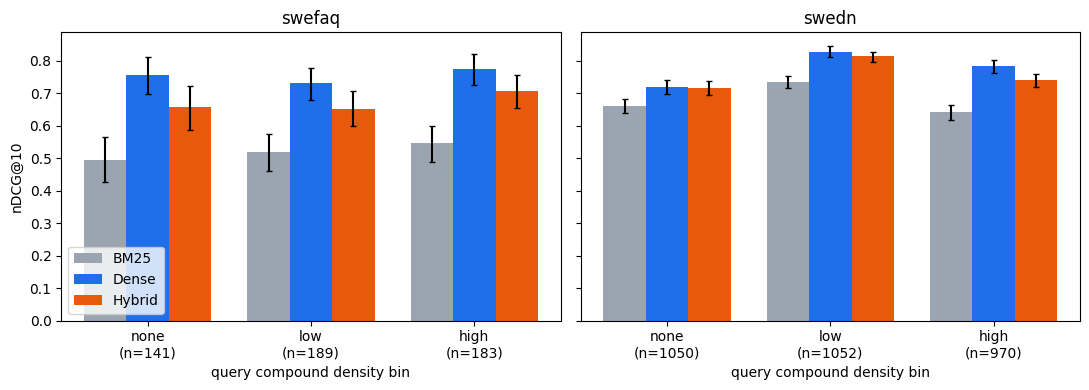

In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {"BM25": "#9aa5b1", "Dense": "#1f6feb", "Hybrid": "#e8590c"}
for ax, ds in zip(axes, ["swefaq", "swedn"]):
    sub = qbin[qbin.ds == ds]; bins = sorted(sub.bin.unique()); x = np.arange(len(bins)); w = 0.26
    for i, meth in enumerate(["BM25", "Dense", "Hybrid"]):
        s = sub[sub.method == meth].set_index("bin").reindex(bins)
        ax.bar(x + (i - 1) * w, s.ndcg10, w, yerr=[s.ndcg10 - s.ci_lo, s.ci_hi - s.ndcg10], capsize=2, label=meth, color=colors[meth])
    ax.set_xticks(x); ax.set_xticklabels([f"{b[2:]}\n(n={int(sub[sub.bin==b].n.iloc[0])})" for b in bins])
    ax.set_title(ds); ax.set_xlabel("query compound density bin")
axes[0].set_ylabel("nDCG@10"); axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, "compound_density_bins.png"), dpi=200); plt.show()

## 7. Examples (error-analysis-er jonno)
Prottek dataset-e high-density query jekhane BM25 / Dense kharap korse. Ekhane thekei `rundgång`-type example nibo.

In [18]:
ex = long[(long.q_bin == "2_high")].pivot_table(index=["ds", "qid"], columns="method", values="ndcg10").reset_index()
ex["query"] = [query_text[d][q] for d, q in zip(ex.ds, ex.qid)]
ex["bm25_minus_dense"] = ex.BM25 - ex.Dense
print("Dense bhalo, BM25 kharap (compound-heavy):")
print(ex.sort_values("bm25_minus_dense").head(8)[["ds", "BM25", "Dense", "query"]].to_string(index=False))
print("\nBM25 bhalo, Dense kharap (compound-heavy):")
print(ex.sort_values("bm25_minus_dense").tail(8)[["ds", "BM25", "Dense", "query"]].to_string(index=False))

Dense bhalo, BM25 kharap (compound-heavy):
    ds  BM25  Dense                                                                                                                                                                                                        query
swefaq   0.0    1.0                                                                                                                                                                                      Vad betyder "lösenord"?
swefaq   0.0    1.0                                                                                                                                            Hur ansöker jag om ett id-kort (identitetskort) hos Skatteverket?
swefaq   0.0    1.0                                                                                                                                                                         Hur är ett lägenhetsnummer uppbyggt?
swefaq   0.0    1.0                                  Jag 

## Save
`results/` e save hoyeche: `compound_validation_sample.csv`, `compound_splitter_validation.csv`, `compound_density_per_query.csv`, `compound_bins_query.csv`, `compound_bins_doc.csv`, `compound_bins_paired_diff.csv`, `compound_regression.csv`, `compound_density_bins.png`.
**"Save & Run All"** koro, tarpor ei notebook-er output-er pashapashi `sv_freq.json` ar `cp_cache.json` (cache) o save thakbe.
Ekhon ei notebook-er shob table/screenshot amake pathao, tarpor Step 5 (M1/M2/M3) e jabo.